# 4. Correlation and Association

Use this notebook to explore how car features relate to one another and to car price. Choose columns from your dataset, make the plots, and write down what you notice. A relationship does not prove that one variable causes another.

## 4.1 Load the data

Start with the cleaned car dataset. Check the first few rows and the column names so you can choose suitable variables in the sections below.

In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATASET_PATH = Path("../data/final_destination.csv")
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Place the cleaned CarDekho CSV at {DATASET_PATH.resolve()}")

df = pd.read_csv(DATASET_PATH)
display(df.head())
display(df.dtypes.rename("data type").to_frame())

,model,vehicle_age,km_driven,seller_type,transmission_type,mileage,engine,max_power,selling_price,real_typical_owner_type,real_avg_owner_count,real_common_trim,real_new_ex_showroom_price,real_body_type,model_grouped
0,Alto,9,120000,Individual,Manual,19.70,796,46.30,120000,First,1.15,LXi,0.519500,Unknown,Alto
1,Grand,5,20000,Individual,Manual,18.90,1197,82.00,550000,First,1.08,i10 Sportz,0.641574,Hatchback,Grand
2,i20,11,60000,Individual,Manual,17.00,1197,80.00,215000,First,1.18,1.2 Magna,0.820343,Hatchback,i20
3,Alto,9,37000,Individual,Manual,20.92,998,67.10,226000,First,1.15,LXi,0.519500,Unknown,Alto
4,Ecosport,6,30000,Dealer,Manual,22.77,1498,98.59,570000,First,1.08,1.5 DV5 MT Titanium Optional,0.856000,SUV,Ecosport


,data type
model,str
vehicle_age,int64
km_driven,int64
seller_type,str
transmission_type,str
mileage,float64
engine,int64
max_power,float64
selling_price,int64
real_typical_owner_type,str


## 4.2 Explore relationships between numerical variables

Choose two numerical columns, such as a car feature and its price. Use a scatter plot to look for an upward, downward, straight-line, or curved pattern. A regression line can help show the general direction, but it may not fit every kind of relationship.

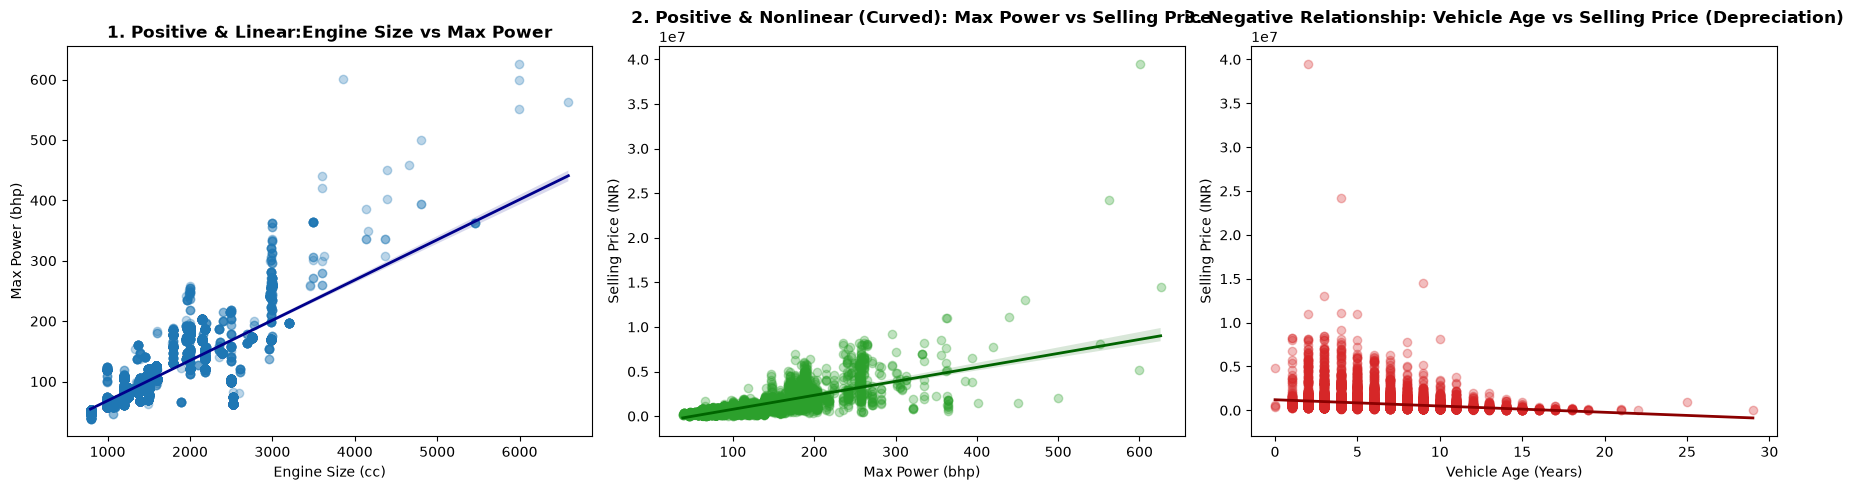

In [24]:
# 4.2 Numerical Relationships: Positive, Negative, Linear, and Nonlinear Relationships
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Positive & Linear Relationship: Engine Size vs Max Power
sns.regplot(
    data=df, x="engine", y="max_power", ax=axes[0],
    scatter_kws={"alpha": 0.3, "color": "#1f77b4"},
    line_kws={"color": "darkblue", "linewidth": 2}
)
axes[0].set_title("1. Positive & Linear:Engine Size vs Max Power", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Engine Size (cc)")
axes[0].set_ylabel("Max Power (bhp)")

# 2. Positive & Nonlinear (Curved) Relationship: Max Power vs Selling Price
sns.regplot(
    data=df, x="max_power", y="selling_price", ax=axes[1],
    scatter_kws={"alpha": 0.3, "color": "#2ca02c"},
    line_kws={"color": "darkgreen", "linewidth": 2}
)
axes[1].set_title("2. Positive & Nonlinear (Curved): Max Power vs Selling Price", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Max Power (bhp)")
axes[1].set_ylabel("Selling Price (INR)")

# 3. Negative Relationship: Vehicle Age vs Selling Price (Depreciation)
sns.regplot(
    data=df, x="vehicle_age", y="selling_price", ax=axes[2],
    scatter_kws={"alpha": 0.3, "color": "#d62728"},
    line_kws={"color": "darkred", "linewidth": 2}
)
axes[2].set_title("3. Negative Relationship: Vehicle Age vs Selling Price (Depreciation)", fontsize=12, fontweight="bold")
axes[2].set_xlabel("Vehicle Age (Years)")
axes[2].set_ylabel("Selling Price (INR)")

plt.tight_layout()
plt.show()


In [19]:
numerical_columns = df.select_dtypes(include=["number"]).columns
print("Numerical columns in the dataset:" , numerical_columns.tolist())

Numerical columns in the dataset: ['vehicle_age', 'km_driven', 'mileage', 'engine', 'max_power', 'selling_price', 'real_avg_owner_count', 'real_new_ex_showroom_price']


## 4.3 Compare numerical variables with a correlation matrix

Calculate correlations for the numerical columns and display them as a heatmap. Values near 1 show a strong positive relationship, values near -1 show a strong negative relationship, and values near 0 show a weak straight-line relationship. Correlation may miss curved patterns.

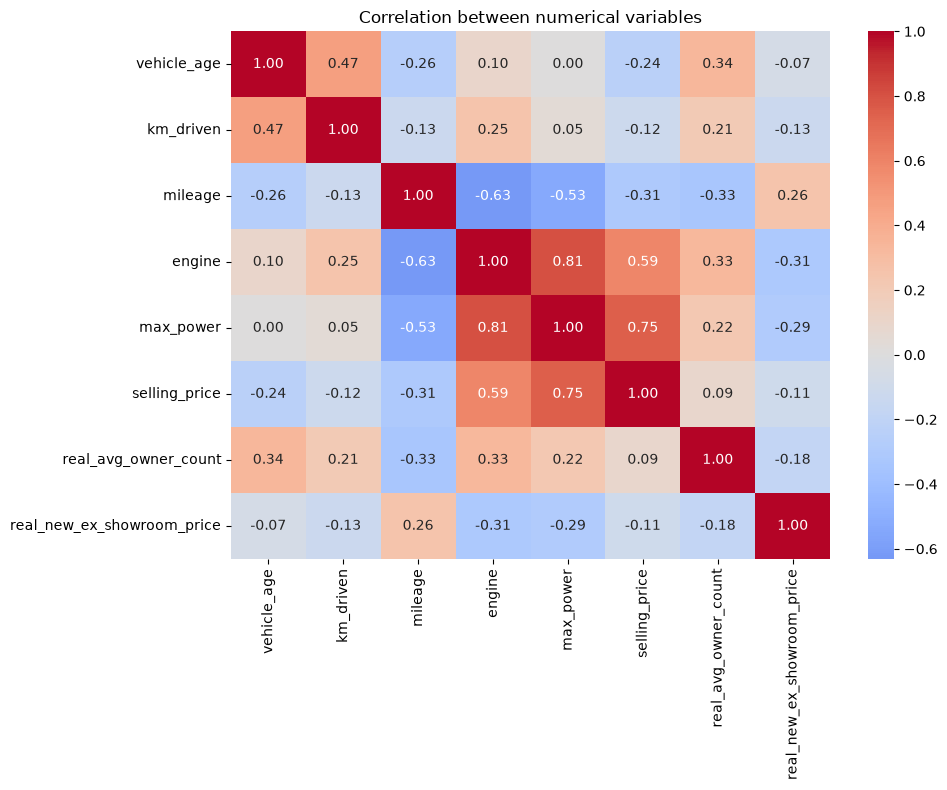

In [20]:
numeric_df = df.select_dtypes(include="number")
correlations = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numerical variables")
plt.tight_layout()
plt.show()

## 4.4 Explore relationships between categorical variables

Choose two categorical columns, such as fuel type and transmission. Compare the categories with a grouped bar chart or a 100% stacked bar chart. Look for groups that appear more or less often together. Use a count chart for totals, or a normalized chart to compare proportions.

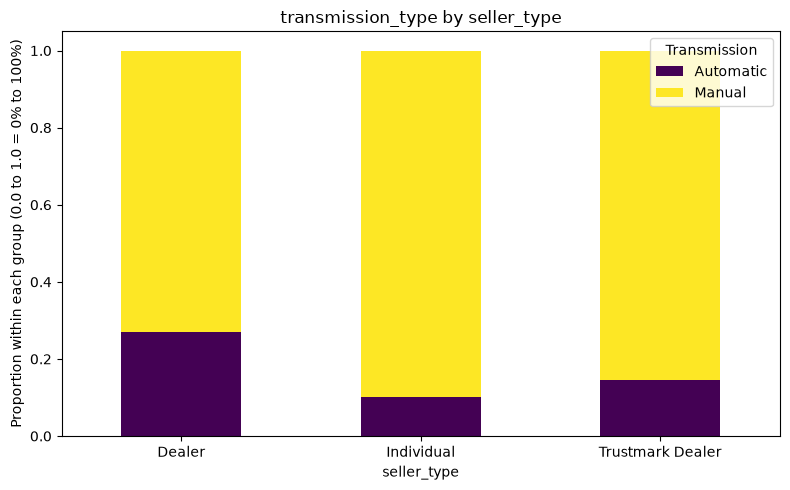

In [21]:
# 1. Choose two categorical columns to compare
first_category = "seller_type"
second_category = "transmission_type"

# 2. Calculate the proportion of each transmission type per seller type
category_shares = pd.crosstab(
    df[first_category], df[second_category], normalize="index"
)

# 3. Plot as a 100% stacked bar chart
category_shares.plot(kind="bar", stacked=True, figsize=(8, 5), colormap="viridis")
plt.ylabel("Proportion within each group (0.0 to 1.0 = 0% to 100%)")
plt.title(f"{second_category} by {first_category}")
plt.xticks(rotation=0)
plt.legend(title="Transmission")
plt.tight_layout()
plt.show()

## 4.5 Check for highly related predictor variables

If you plan to use regression, look for predictor variables that are strongly related to each other. Use the correlation heatmap above and a pair plot for a closer look. Highly related predictors can make it harder to understand each variable's separate contribution.

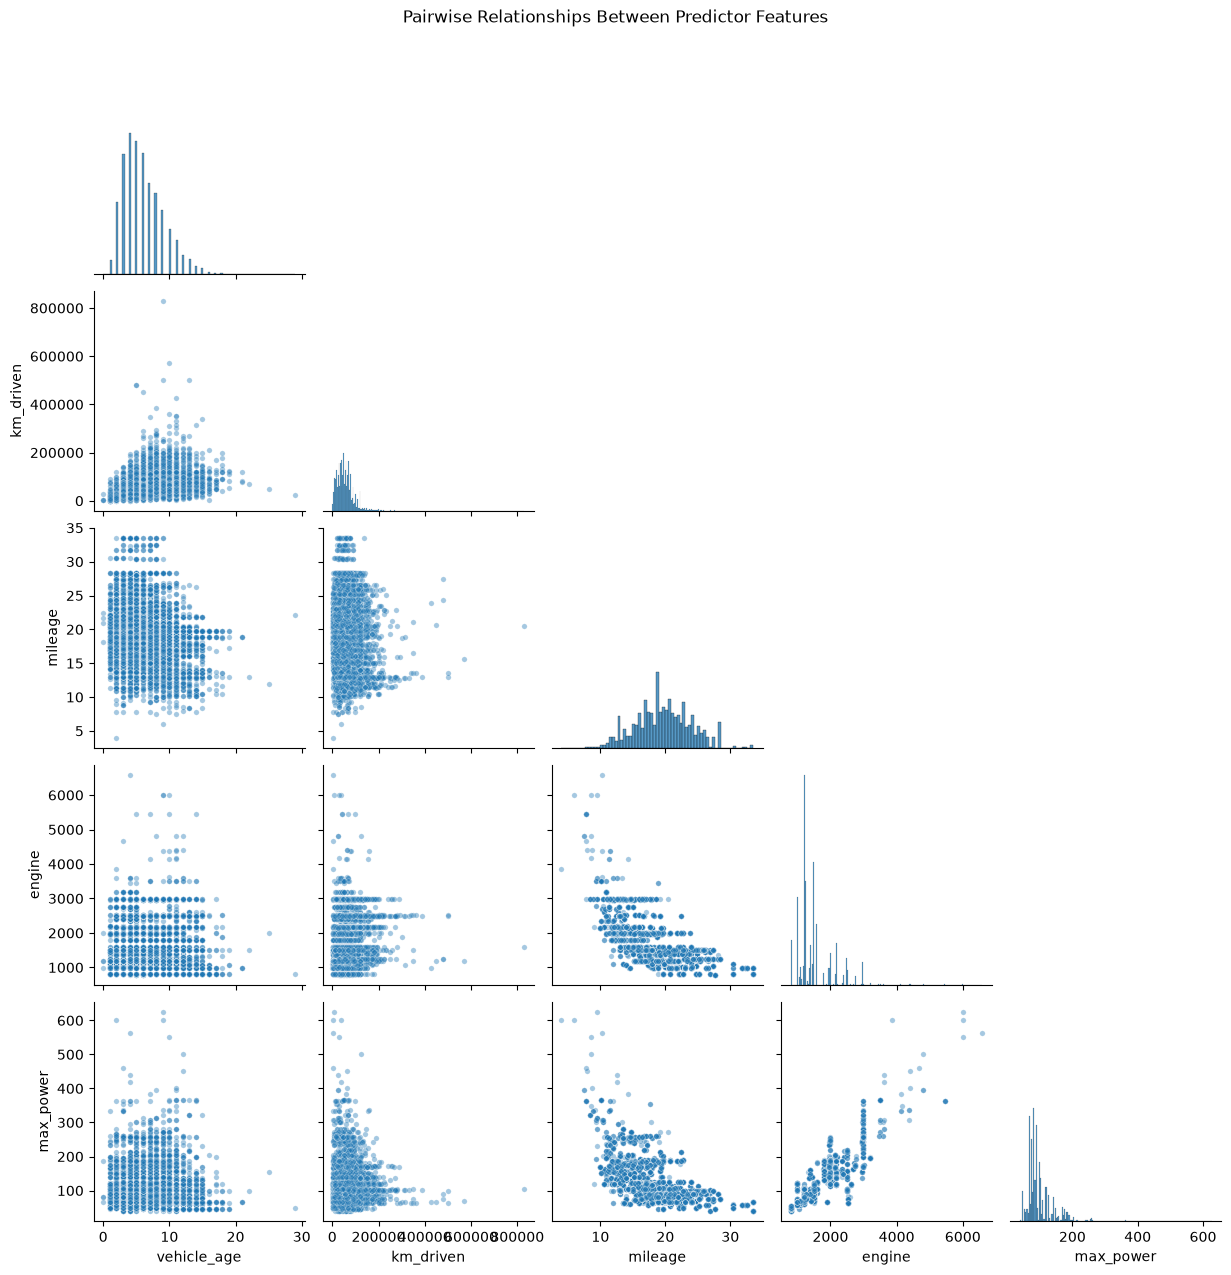

In [22]:
# Choose numerical predictor columns (features) - excluding 'selling_price'
predictor_columns = ["vehicle_age", "km_driven", "mileage", "engine", "max_power"]

# Generate a pair plot to visualize pairwise relationships and check for collinearity
sns.pairplot(df[predictor_columns], corner=True, plot_kws={"alpha": 0.4, "s": 15})
plt.suptitle("Pairwise Relationships Between Predictor Features", y=1.02)
plt.show()

## 4.6 Write down what you found

- Which numerical variables had the clearest relationship with car price?
- Did any scatter plot show a curved pattern or unusual points?
- Which categorical groups seemed to occur together most often?
- Did you find predictor variables that were strongly related to each other?
- What is one important limit of these results?

### Key Findings and Interpretations:

1. **Strongest relationship with car price:**
   - **`max_power`** and **`engine`** display the strongest positive correlation with `selling_price` (as power/displacement rises, price increases).
   - **`vehicle_age`** has a notable negative correlation (older vehicles sell for less due to depreciation).

2. **Curved patterns and outliers:**
   - The relationship between engine/power and price is non-linear (curved/exponential). While budget and mid-tier cars increase moderately in price, high-end luxury/sports models shoot up dramatically, showing variance that fans out (heteroscedasticity) and high-value outliers.

3. **Categorical co-occurrences:**
   - Individual sellers predominantly sell **Manual** transmission cars.
   - Commercial **Dealers** carry a noticeably higher share of **Automatic** transmission cars compared to individuals.

4. **Highly related predictor variables (Multicollinearity):**
   - **`engine`** and **`max_power`** are very strongly positively correlated ($r > 0.7$). Larger engines almost always generate higher horsepower.
   - **`mileage`** (fuel efficiency) is negatively correlated with both `engine` and `max_power` (bigger, more powerful engines consume more fuel).
   - *Note for modeling:* Including both `engine` and `max_power` in a linear regression model may introduce multicollinearity; one of them might be sufficient.

5. **Important limitation:**
   - **Correlation $\neq$ Causation.** Just because a feature correlates with price doesn't mean it directly dictates price on its own. For instance, brand prestige, vehicle condition, accident history, and regional demand heavily influence value regardless of raw mechanical specs.